### ***Graph State String***

In [1]:
from langgraph.graph import StateGraph,START,END 

# creating node 
def greeting(state:str) -> str:
    """this function greets people to AI World"""
    return state + "welcome to Indus AI Carrer..!"

builder = StateGraph(str)

# add nodes 
builder.add_node("greeting",greeting)

# add edges 
builder.add_edge(START,"greeting")
builder.add_edge("greeting",END)

graph = builder.compile()

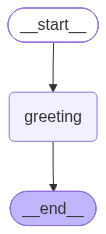

In [2]:
graph

In [3]:
print(graph.invoke("Hello am Ankit "))

Hello am Ankit welcome to Indus AI Carrer..!


### ***Graph State Dictionary***

In [4]:

from langgraph.graph import StateGraph,START,END 
from typing_extensions import TypedDict

class State(TypedDict):
     graph_str:str 


def greeting(state:State) -> State:
     """function takes a dict and return a dict with greeting"""
     return {"graph_str": state["graph_str"]+" welcome to Indus AI Lab..!"}

graph = StateGraph(State)
graph.add_node("greeting",greeting)
graph.add_edge(START,"greeting")
graph.add_edge("greeting",END)

g = graph.compile()

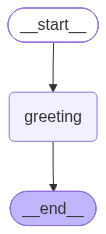

In [5]:
g

In [6]:
print(g.invoke({"graph_str": "Hello am Ankit"}))

{'graph_str': 'Hello am Ankit welcome to Indus AI Lab..!'}


### ***Conditional Edges***

In [7]:
from langgraph.graph import START,END,StateGraph
from typing_extensions import TypedDict
from typing import Literal 

class State(TypedDict):
     graph_str :str 

def node1(state:State) -> State:
     """this node greet our user"""
     return {"graph_str": state["graph_str"] + "Welcome To Indus AI World"}

def node2(state:State) -> State:
     """this node greet our user"""
     return {"graph_str": state["graph_str"] + "I am in Node 2"}

def node3(state:State) -> State:
     """this node greet our user"""
     return {"graph_str": state["graph_str"] + "I am in Node 3"}

# condtional edges 
def next_step(state:State) -> Literal["node2","node3"]:
     """guide the state/graph to next node"""
     state_str = state["graph_str"]
     array_state_str = state_str.split(" ")

     if array_state_str[0] == "hello":
          return "node2"

     return "node3"

# Build Graph  
build = StateGraph(State)
build.add_node("node1",node1)
build.add_node("node2",node2)
build.add_node("node3",node3)

build.add_edge(START,"node1")
build.add_conditional_edges("node1",next_step)
build.add_edge("node2",END)
build.add_edge("node3",END)

g = build.compile()

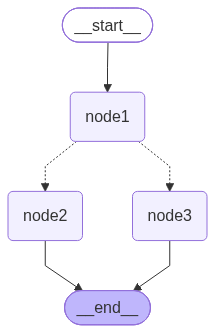

In [8]:
g

In [9]:
# Example 1: Execute node2
result1 = g.invoke({
    "graph_str": "hello Ankit "
})
print(result1["graph_str"])

# Example 2: Execute node3
result2 = g.invoke({
    "graph_str": "Good morning Ankit "
})
print(result2["graph_str"])

hello Ankit Welcome To Indus AI WorldI am in Node 2
Good morning Ankit Welcome To Indus AI WorldI am in Node 3


### ***Graph Introduction Model***

In [10]:
from langgraph.graph import START,END,StateGraph
from typing_extensions import TypedDict
from typing import Literal,NotRequired
from langchain_groq import ChatGroq 
from dotenv import load_dotenv
load_dotenv()


class State(TypedDict):
     graph_int:NotRequired[int]
     graph_str :str 

model_llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0
)

def node1(state: State) -> State:
    """take a state and ask our model to pick a number between 1 or 2"""
    model_response = model_llm.invoke("choose between 1 or 3 or 2. reply only with a number")

    if isinstance(int(model_response.content), int):
        return {"graph_int":int(model_response.content),
                "graph_str": state["graph_str"] + "passed by node 1"}
    return {"graph_int":0,
                "graph_str": state["graph_str"] + "passed by node 1"}

def node2(state: State) -> State:
    """take a state and ask our model to pick a number between 1 or 2"""
    return {"graph_int":state["graph_int"],
                "graph_str": state["graph_str"] + "passed by node 2"}

def node3(state: State) -> State:
    """take a state and ask our model to pick a number between 1 or 2"""
    return {"graph_int":state["graph_int"],
                "graph_str": state["graph_str"] + "passed by node 3"}

# condtional edges 
def next_step(state:State) -> Literal["node2","node3",END]:
    """check state and return which node to go"""
    number_state = state["graph_int"]
    if number_state == 2:
        return "node2"
    elif number_state == 3:
        return "node3"
    else:
        return END

# Build Graph  
builder = StateGraph(State)

builder.add_node("node1", node1)
builder.add_node("node2", node2)
builder.add_node("node3", node3)

builder.add_edge(START, "node1")
builder.add_conditional_edges("node1", next_step)
builder.add_edge("node2", END)
builder.add_edge("node3", END)

graph = builder.compile()

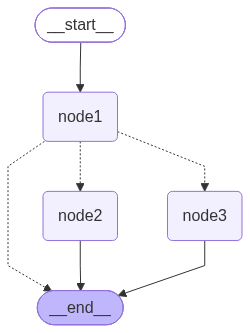

In [11]:
graph

In [12]:
# Run the graph
initial_state = {
    "graph_str": "Starting workflow: "
}

result = graph.invoke(initial_state)

print("Final State:", result)
print("Selected Number:", result.get("graph_int"))
print("Execution Path:", result["graph_str"])

Final State: {'graph_int': 2, 'graph_str': 'Starting workflow: passed by node 1passed by node 2'}
Selected Number: 2
Execution Path: Starting workflow: passed by node 1passed by node 2


### ***Graph Message State***

In [13]:
from langgraph.graph import StateGraph, START, END, MessagesState
from langchain_core.messages import HumanMessage
from langchain_groq import ChatGroq
from dotenv import load_dotenv

load_dotenv()

model_llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0
)

# Node
def chat(state: MessagesState) -> MessagesState:
    response = model_llm.invoke(state["messages"])
    return {"messages": [response]}

# Build graph
builder = StateGraph(MessagesState)
builder.add_node("chat", chat)

builder.add_edge(START, "chat")
builder.add_edge("chat", END)

g = builder.compile()

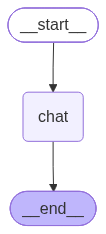

In [14]:
g

In [15]:
result = g.invoke({
    "messages": [
        HumanMessage(content="My name is Ankit.")
    ]
})

print(result["messages"][-1].content)

Nice to meet you, Ankit! How can I help you today?


### ***Graph Model Tool***

In [16]:
import warnings
warnings.filterwarnings("ignore")

from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.prebuilt import ToolNode, tools_condition
from langchain_groq import ChatGroq
from langchain.tools import tool
from dotenv import load_dotenv

load_dotenv()

# 1. Initialize the LLM
llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0
)

# 2. Define tools
@tool
def multiply(a: int, b: int) -> int:
    """Multiply two numbers and return the product."""
    return a * b


@tool
def add(a: int, b: int) -> int:
    """Add two numbers and return the sum."""
    return a + b


tools = [multiply, add]

# 3. Bind tools to the model
llm_with_tools = llm.bind_tools(tools)


# 4. Define the chatbot node
def chat_with_tool(state: MessagesState):
    response = llm_with_tools.invoke(state["messages"])
    return {"messages": [response]}


# 5. Create the graph
builder = StateGraph(MessagesState)

builder.add_node("chat_with_tool", chat_with_tool)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "chat_with_tool")

# Execute tools when requested by the model
builder.add_conditional_edges(
    "chat_with_tool",
    tools_condition
)

# Return tool results to the model
builder.add_edge("tools", "chat_with_tool")

# 6. Compile the graph
g = builder.compile()

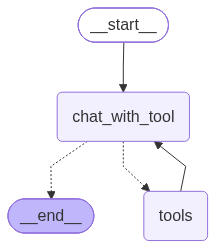

In [17]:
g

In [18]:
from langchain_core.messages import HumanMessage

initial_state = {
    "messages": [
        HumanMessage(
            content="What is 25 multiplied by 4?"
        ),
    ],
}

result = g.invoke(initial_state)
print(result["messages"][-1].content)

25 multiplied by 4 equals **100**.


### ***Graph Tool Call***

In [19]:
from langgraph.graph import StateGraph,START,END,MessagesState
from langchain_groq import ChatGroq 
from langgraph.prebuilt import ToolNode,tools_condition

from dotenv import load_dotenv
load_dotenv()

llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0
)


@tool
def add(a: int, b: int) -> int:
    """Add two numbers and return the sum."""
    return a + b

llm_with_tool = model_llm.bind_tools([add])

def chat_with_tool(state: MessagesState):
    response = llm_with_tools.invoke(state["messages"])
    return {"messages": [response]}


# create graph 
builder = StateGraph(MessagesState)

builder.add_node("chat_with_tool", chat_with_tool)
builder.add_node("tools", ToolNode([add]))

builder.add_edge(START, "chat_with_tool")
builder.add_conditional_edges("chat_with_tool", tools_condition)
builder.add_edge("tools",END)

graph = builder.compile()

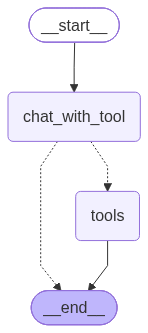

In [20]:
graph

In [21]:
result = graph.invoke({
    "messages": [
        HumanMessage(
            content="What is 25 plus 15? Use the add tool."
        )
    ]
})

print(result["messages"][-1].content)

40


### ***Graph Agent***

In [25]:
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.prebuilt import ToolNode, tools_condition
from langchain_core.messages import HumanMessage, SystemMessage
from langchain.tools import tool
from langchain_groq import ChatGroq
from dotenv import load_dotenv

load_dotenv()

# Initialize model
llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0
)

# Define tools
@tool
def addition(a: float, b: float) -> float:
    """Add two numbers."""
    return a + b

@tool
def subtraction(a: float, b: float) -> float:
    """Subtract b from a."""
    return a - b

@tool
def division(a: float, b: float) -> float:
    """Divide a by b. b must not be zero."""
    if b == 0:
        raise ValueError("Cannot divide by zero.")
    return a / b

# Use the SAME list everywhere
tools = [addition, subtraction, division]

llm_with_tools = llm.bind_tools(tools)

system_message = SystemMessage(
    content="You are a helpful maths teacher. Use the tools for calculations."
)

def chat_with_tools(state: MessagesState):
    messages = [system_message] + state["messages"]
    response = llm_with_tools.invoke(messages)
    return {"messages": [response]}

# Build graph
builder = StateGraph(MessagesState)

builder.add_node("chat_with_tools", chat_with_tools)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "chat_with_tools")
builder.add_conditional_edges("chat_with_tools", tools_condition)
builder.add_edge("tools", "chat_with_tools")

g = builder.compile()

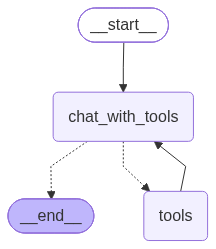

In [26]:
g

In [27]:
# Example 1: Addition
result = g.invoke({
    "messages": [
        HumanMessage(content="Calculate 25 + 15 using your tool.")
    ]
})
print(result["messages"][-1].content)

The sum of 25 and 15 is **40**.


In [28]:
# Example 2: Subtraction
result = g.invoke({
    "messages": [
        HumanMessage(content="Calculate 50 - 20 using your tool.")
    ]
})
print(result["messages"][-1].content)

The result of \(50 - 20\) is **30**.


In [29]:
# Example 3: Division
result = g.invoke({
    "messages": [
        HumanMessage(content="Calculate 100 divided by 4 using your tool.")
    ]
})
print(result["messages"][-1].content)

The result of \(100 \div 4\) is **25**.


### ***Graph Agent With Memory***

In [30]:
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.prebuilt import ToolNode, tools_condition
from langchain_core.messages import HumanMessage, SystemMessage
from langchain.tools import tool
from langchain_groq import ChatGroq
from langgraph.checkpoint.memory import MemorySaver

from dotenv import load_dotenv
load_dotenv()

# Initialize model
llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0
)

# Define tools
@tool
def addition(a: float, b: float) -> float:
    """Add two numbers."""
    return a + b

@tool
def subtraction(a: float, b: float) -> float:
    """Subtract b from a."""
    return a - b

@tool
def division(a: float, b: float) -> float:
    """Divide a by b. b must not be zero."""
    if b == 0:
        raise ValueError("Cannot divide by zero.")
    return a / b

# Use the SAME list everywhere
tools = [addition, subtraction, division]

llm_with_tools = llm.bind_tools(tools)

system_message = SystemMessage(
    content="You are a helpful maths teacher. Use the tools for calculations."
)

def chat_with_tools(state: MessagesState):
    messages = [system_message] + state["messages"]
    response = llm_with_tools.invoke(messages)
    return {"messages": [response]}

# Build graph
builder = StateGraph(MessagesState)

builder.add_node("chat_with_tools", chat_with_tools)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "chat_with_tools")
builder.add_conditional_edges("chat_with_tools", tools_condition)
builder.add_edge("tools", "chat_with_tools")

memory = MemorySaver()
g = builder.compile(checkpointer=memory)
config = {"configurable": {"thread_id": "1"}}

messages = [HumanMessage(content="multiply 5544 with 654.")]

In [31]:
response = graph.invoke({"messages": messages},config)
print(response["messages"][-1].content)

The product of 5544 and 654 is:

**3,625,776**
